# Module 10 – Capstone: Why are ShopKart returns eating our profit?
**Video 10.2 – Build it: SQL → pandas → charts → model** (plan made in Video 10.1)

**The brief from the manager:** *"Returns are eating our profit. What's going on, and can we predict them?"*

**Goal of this notebook:** answer that brief end to end, using everything from the course:
1. SQL – pull one joined table from the ShopKart database (Module 4)
2. pandas – check and prepare the data (Module 6)
3. Charts – 4 charts about returns (Module 8)
4. Money – how much revenue is lost to returns, in ₹
5. Model – predict which orders will be returned, and check how good it is (Module 9)
6. Insights + recommendations for the manager (Module 8 storytelling)

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file.
Then click the **folder icon** on the left and drag **`shopkart.db`** into it. Wait until the upload finishes, then Runtime → Run all.

## Step 0 – Import the libraries
`sqlite3` is built into Python – it lets us talk to a `.db` file using SQL. Everything else you already know.

In [1]:
import sqlite3                      # talk to the SQLite database
import pandas as pd                 # tables
import matplotlib.pyplot as plt     # charts
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

pd.set_option("display.max_columns", 30)
print("Libraries ready")

Libraries ready


## Step 1 – Load data with SQL
This is **exactly Q3 from `M10_capstone_shopkart.sql`**. We join three tables in SQL and get back one pandas DataFrame.
- `orders` gives the order details and whether it was returned
- `products` gives category and cost price
- `customers` gives membership, age and gender

`pd.read_sql(query, con)` runs the SQL and returns a DataFrame.

In [2]:
# 1. Open a connection to the database file (it must be in the Colab folder)
con = sqlite3.connect("shopkart.db")

# 2. The SQL query (same as Q3 in the .sql file)
query = """
SELECT o.order_id, o.order_date, o.customer_id, o.product_id,
       o.quantity, o.unit_price, o.discount, o.city, o.payment_mode,
       o.delivery_days, o.rating, o.returned,
       p.product_name, p.category, p.cost_price,
       c.gender, c.age, c.membership,
       ROUND(o.quantity * o.unit_price * (1 - o.discount), 2) AS revenue
FROM orders AS o
INNER JOIN products AS p ON o.product_id = p.product_id
LEFT JOIN customers AS c ON o.customer_id = c.customer_id
ORDER BY o.order_id;
"""

# 3. Run the query and get a DataFrame back
df = pd.read_sql(query, con)
con.close()

print(df.shape)
df.head()

(5000, 19)


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,city,payment_mode,delivery_days,rating,returned,product_name,category,cost_price,gender,age,membership,revenue
0,O10001,2025-01-01,C0593,P048,6,362,0.20,Delhi,COD,4,2.0,N,Wings of Fire,Books,240,Female,26,Prime,1737.6
1,O10002,2025-01-01,C0367,P049,2,300,0.05,Chennai,Debit Card,4,5.0,N,Face Wash,Beauty,150,Male,35,Free,570.0
2,O10003,2025-01-01,C0707,P020,1,2258,0.05,Delhi,Debit Card,2,3.0,N,Saree,Fashion,1280,Male,41,Prime,2145.1
3,O10004,2025-01-01,C0118,P026,2,2020,0.15,Lucknow,COD,4,4.0,Y,Pressure Cooker,Home,1260,Male,35,Free,3434.0
4,O10005,2025-01-01,C0238,P026,2,1937,0.10,Chennai,UPI,2,4.0,N,Pressure Cooker,Home,1260,Female,33,Free,3486.6


## Step 2 – Check the data before trusting it
A good analyst never jumps to charts. We check: number of rows, types, missing values, duplicates, and the values in `returned`.

Note: this database holds the **cleaned** orders from Module 2/6, so we expect it to be tidy. We still check.

In [3]:
print("Rows, columns:", df.shape)
print("Duplicate order_ids:", df["order_id"].duplicated().sum())
print()
print("Missing values per column (only columns with some missing):")
missing = df.isnull().sum()
print(missing[missing > 0])
print()
print("Values in returned:", df["returned"].value_counts().to_dict())

Rows, columns: (5000, 19)
Duplicate order_ids: 0

Missing values per column (only columns with some missing):
rating    260
dtype: int64

Values in returned: {'N': 4313, 'Y': 687}


**What we found:** 5,000 orders, no duplicate order IDs, `returned` is only Y/N.
The only missing values are in `rating` (customers who did not rate). We keep them missing – and we will **not** use rating in the model anyway (see Step 6: rating is given *after* the return happens, so it would be cheating).

## Step 3 – Prepare columns
- `order_date` → real date
- `is_returned` → 1 if returned, 0 if not (numbers are easier to average: the mean of a 0/1 column **is** the return rate)
- `profit` → revenue − quantity × cost_price
- `delivery_band` → group delivery days into 5 bands (some single days have only 1–2 orders)

In [4]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["is_returned"] = (df["returned"] == "Y").astype(int)
df["profit"] = df["revenue"] - df["quantity"] * df["cost_price"]

df["delivery_band"] = pd.cut(df["delivery_days"],
                             bins=[0, 3, 4, 5, 7, 30],
                             labels=["2-3 days", "4 days", "5 days", "6-7 days", "8+ days"])

overall_rate = df["is_returned"].mean()
print(f"Overall return rate: {overall_rate:.1%}")
print(f"Returned orders: {df['is_returned'].sum()} of {len(df)}")
print(f"Total revenue: ₹{df['revenue'].sum():,.0f}   Total profit: ₹{df['profit'].sum():,.0f}")

Overall return rate: 13.7%
Returned orders: 687 of 5000
Total revenue: ₹14,704,650   Total profit: ₹3,140,750


## Step 4 – EDA: where do returns happen?
One helper function makes a return-rate table for any column, so we do not repeat code four times.

In [5]:
def return_table(column):
    """Orders, returns and return rate (%) for each value of a column."""
    t = df.groupby(column, observed=True).agg(orders=("order_id", "count"),
                                               returns=("is_returned", "sum"),
                                               return_rate=("is_returned", "mean"))
    t["return_rate"] = (t["return_rate"] * 100).round(1)
    return t

def bar_chart(table, title, highlight=None, sort=True):
    """Horizontal bar chart of return rate with a dashed line for the overall average."""
    t = table.sort_values("return_rate") if sort else table.iloc[::-1]
    colors = ["#E76F51" if name == highlight else "#9AA8BC" for name in t.index]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(t.index.astype(str), t["return_rate"], color=colors)
    ax.axvline(overall_rate * 100, color="#1B2433", linestyle="--", linewidth=1)
    ax.text(overall_rate * 100 + 0.3, -0.6, f"Overall {overall_rate:.1%}", fontsize=9)
    for i, v in enumerate(t["return_rate"]):
        ax.text(v + 0.3, i, f"{v}%", va="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=13)
    ax.set_xlabel("Return rate (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

### Chart 1 – Return rate by city

           orders  returns  return_rate
city                                   
Pune          451      146         32.4
Kolkata       414       59         14.3
Ahmedabad     303       43         14.2
Lucknow       326       44         13.5
Jaipur        270       36         13.3
Chennai       442       56         12.7
Hyderabad     495       63         12.7
Bengaluru     736       89         12.1
Delhi         804       82         10.2
Mumbai        759       69          9.1


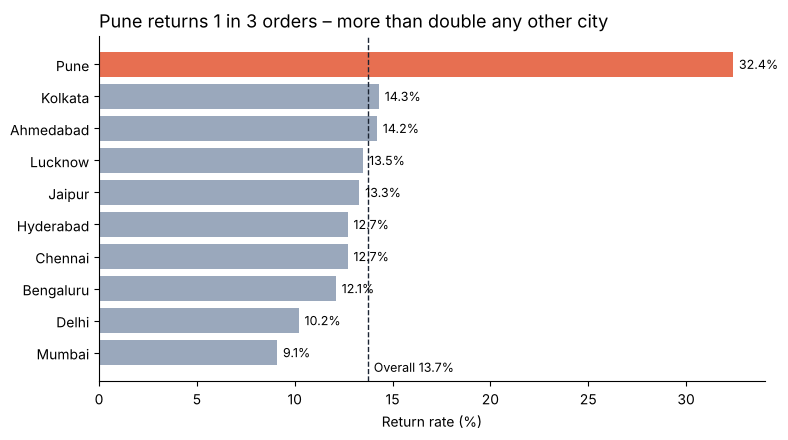

In [6]:
by_city = return_table("city")
print(by_city.sort_values("return_rate", ascending=False))
bar_chart(by_city, "Pune returns 1 in 3 orders – more than double any other city", highlight="Pune")

### Chart 2 – Return rate by category

             orders  returns  return_rate
category                                 
Fashion        1326      279         21.0
Electronics    1152      155         13.5
Home           1020      127         12.5
Beauty          750       71          9.5
Books           752       55          7.3


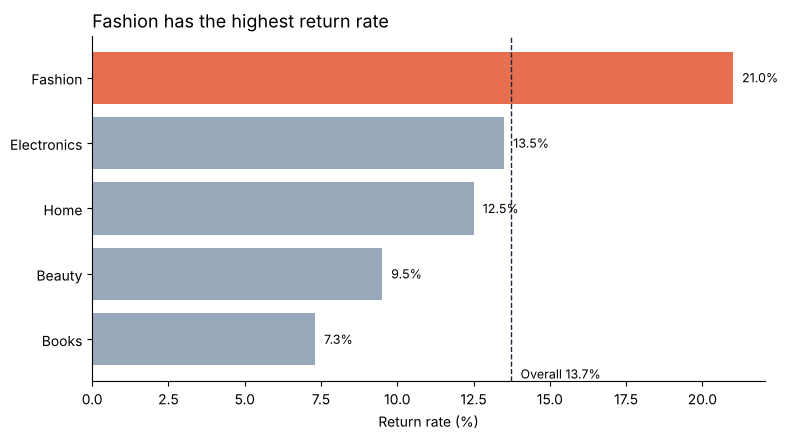

In [7]:
by_cat = return_table("category")
print(by_cat.sort_values("return_rate", ascending=False))
bar_chart(by_cat, "Fashion has the highest return rate", highlight="Fashion")

### Chart 3 – Return rate by payment mode

              orders  returns  return_rate
payment_mode                              
COD              983      188         19.1
Unknown           90       15         16.7
Net Banking      297       39         13.1
Credit Card      888      112         12.6
Debit Card       685       84         12.3
UPI             2057      249         12.1


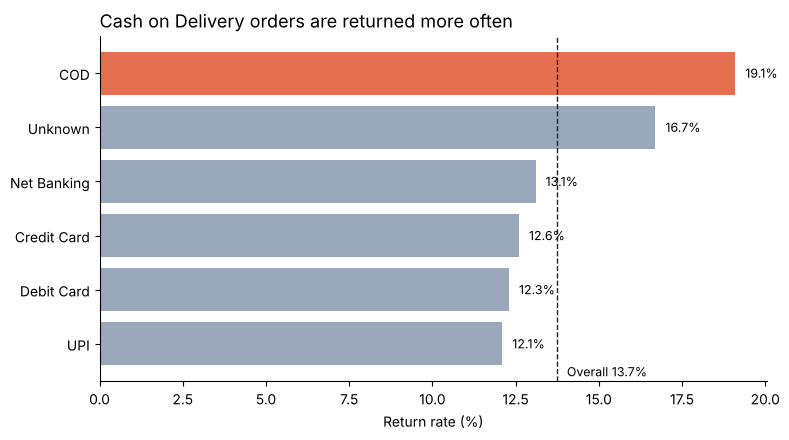

In [8]:
by_pay = return_table("payment_mode")
print(by_pay.sort_values("return_rate", ascending=False))
bar_chart(by_pay, "Cash on Delivery orders are returned more often", highlight="COD")

### Chart 4 – Return rate by delivery time

               orders  returns  return_rate
delivery_band                              
2-3 days         1905      198         10.4
4 days           1210      142         11.7
5 days            942      156         16.6
6-7 days          824      155         18.8
8+ days           119       36         30.3


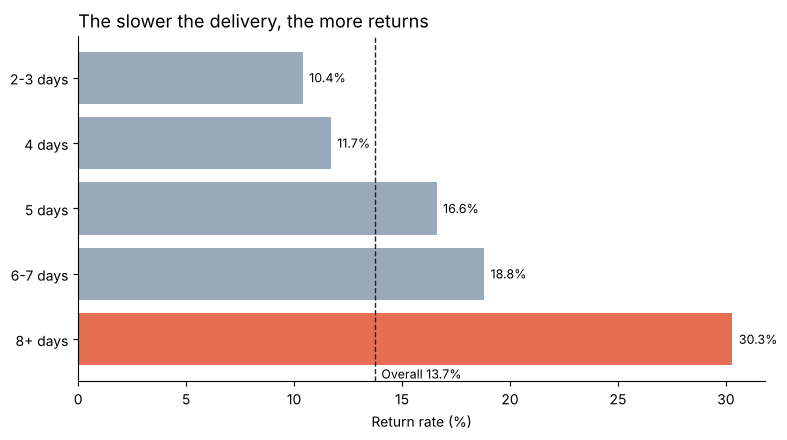

In [9]:
by_del = return_table("delivery_band")
print(by_del)
bar_chart(by_del, "The slower the delivery, the more returns", highlight="8+ days", sort=False)

### A closer look: is Pune just slow?
Pune deliveries are slow – but so are Lucknow and Jaipur. If slow delivery were the whole story, those two cities would also have high returns.

In [10]:
check = df.groupby("city").agg(avg_delivery_days=("delivery_days", "mean"),
                               return_rate=("is_returned", "mean"))
check["return_rate"] = (check["return_rate"] * 100).round(1)
print(check.round(2).sort_values("avg_delivery_days", ascending=False).head(4))
print()
# Pune vs other cities, category by category
df["city_group"] = df["city"].where(df["city"] == "Pune", "Other cities")
pune_vs = (df.pivot_table(index="category", columns="city_group",
                          values="is_returned", aggfunc="mean") * 100).round(1)
print(pune_vs)

           avg_delivery_days  return_rate
city                                     
Pune                    5.77         32.4
Lucknow                 5.75         13.5
Jaipur                  5.63         13.3
Hyderabad               3.81         12.7

city_group   Other cities  Pune
category                       
Beauty                8.3  26.5
Books                 6.2  20.7
Electronics          11.5  33.7
Fashion              19.0  38.8
Home                 10.3  31.7


**Reading it:** Lucknow and Jaipur are almost as slow as Pune, yet their return rates are normal (~13%). And in Pune **every** category is returned 2–4× more than elsewhere. So Pune has a problem of its own (courier partner? packaging? fake orders?) that slow delivery alone does not explain. That is a question for the operations team – data tells us **where** to look, not always **why**.

## Step 5 – Money: how much revenue is lost to returns?
**Definition we use (say it clearly in the deck):**
> *Revenue lost to returns* = total revenue of all returned orders.

**Assumption:** a returned order is refunded in full, so its whole revenue is lost. We ignore return shipping cost and any resale of the returned item – we have no data for them. So this is an **estimate**. We also show the profit those orders would have made.

In [11]:
returned = df[df["is_returned"] == 1]

revenue_lost = returned["revenue"].sum()
profit_lost = returned["profit"].sum()
share = revenue_lost / df["revenue"].sum()

print(f"Revenue lost to returns: ₹{revenue_lost:,.0f}  ({share:.1%} of all revenue)")
print(f"Profit those returned orders would have made: ₹{profit_lost:,.0f}")
print()
lost_by_city = returned.groupby("city")["revenue"].sum().sort_values(ascending=False).round(0)
print("Revenue lost by city (₹):")
print(lost_by_city)
print(f"\nPune share of revenue lost: {lost_by_city['Pune'] / revenue_lost:.1%}")

Revenue lost to returns: ₹2,150,900  (14.6% of all revenue)
Profit those returned orders would have made: ₹460,820

Revenue lost by city (₹):
city
Pune         536752.0
Bengaluru    335693.0
Delhi        267422.0
Mumbai       184125.0
Hyderabad    178041.0
Kolkata      174594.0
Lucknow      144173.0
Ahmedabad    141293.0
Chennai      105909.0
Jaipur        82897.0
Name: revenue, dtype: float64

Pune share of revenue lost: 25.0%


## Step 6 – Can we predict returns?
**Target:** `is_returned` (1/0). **Features:** things we know **at the moment the order is placed**:
category, city, payment mode, delivery days (we treat it as the courier's promised estimate; strictly, the column records actual days, so in a real project use the promised estimate), discount, membership.

**Why NOT rating?** A customer rates *after* receiving – often at the same time as returning. Using rating would be **data leakage**: the model would look great in testing but could never be used on a new order, because the rating does not exist yet.

Text columns must become numbers → `pd.get_dummies` (one 0/1 column per value, `drop_first=True`).

In [12]:
features = ["category", "city", "payment_mode", "delivery_days", "discount", "membership"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["is_returned"]
print("X shape:", X.shape)

# 80% to train, 20% to test. stratify keeps the same return rate in both parts.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Return rate in test set: {y_test.mean():.1%}")

X shape: (5000, 21)
Train: (4000, 21)  Test: (1000, 21)
Return rate in test set: 13.7%


### The accuracy trap
Only about 14% of orders are returned. A lazy "model" that always says **"not returned"** is right about 86% of the time – and catches **zero** returns. So accuracy alone is useless here. We care about **recall** (of the real returns, how many did we catch?) and **precision** (of the orders we flagged, how many really came back?).

`class_weight="balanced"` tells the model to take the rare class (returns) seriously.

In [13]:
baseline_acc = (y_test == 0).mean()
print(f"Baseline 'always No' accuracy: {baseline_acc:.1%}  – recall 0%")
print()

models = {
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({"model": name,
                    "accuracy": round(accuracy_score(y_test, pred), 3),
                    "precision": round(precision_score(y_test, pred), 3),
                    "recall": round(recall_score(y_test, pred), 3)})
    print(name)
    print(confusion_matrix(y_test, pred))
    print()

pd.DataFrame(results)

Baseline 'always No' accuracy: 86.3%  – recall 0%

Decision tree (depth 4)
[[687 176]
 [ 80  57]]

Logistic regression
[[576 287]
 [ 61  76]]



,model,accuracy,precision,recall
0,Decision tree (depth 4),0.744,0.245,0.416
1,Logistic regression,0.652,0.209,0.555


**How to read the confusion matrix** (rows = actual, columns = predicted; order is No, Yes):
`[[true No, false alarm], [missed return, caught return]]`.

### What does the tree use most?

city_Pune           0.372
category_Fashion    0.276
delivery_days       0.104
category_Books      0.102
payment_mode_UPI    0.038
city_Mumbai         0.022
dtype: float64


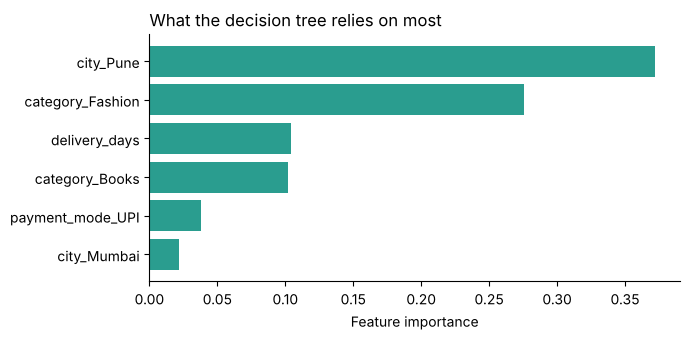

In [14]:
tree = models["Decision tree (depth 4)"]
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(6).round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
top = importance.head(6)[::-1]
ax.barh(top.index, top.values, color="#2A9D8F")
ax.set_title("What the decision tree relies on most", loc="left")
ax.set_xlabel("Feature importance")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Is the model useful?
Logistic regression catches more of the real returns (higher recall); the tree raises fewer false alarms (higher precision). For ShopKart, a **missed return costs more** than an extra confirmation call, so we prefer the higher-recall model.

Honest verdict: this is a **moderate** model, not magic. It cannot see the real reasons (wrong size, damaged item). But it is good enough to **flag risky orders** – for example, send a confirmation call / size-check message before shipping flagged COD orders. The cell below shows how much riskier the flagged orders really are.

In [15]:
logreg = models["Logistic regression"]
flagged = logreg.predict(X_test) == 1
print(f"Orders flagged as risky: {flagged.sum()} of {len(y_test)} ({flagged.mean():.0%})")
print(f"Actual return rate among flagged orders:     {y_test[flagged].mean():.1%}")
print(f"Actual return rate among NOT flagged orders: {y_test[~flagged].mean():.1%}")

Orders flagged as risky: 363 of 1000 (36%)
Actual return rate among flagged orders:     20.9%
Actual return rate among NOT flagged orders: 9.6%


## Step 7 – Insights and recommendations
*(Numbers below are from the outputs above – if you change anything, update them.)*

**Insight 1 – Pune is the biggest leak.** Pune returns 32.4% of orders vs 13.7% overall (about 2.4×). It has 9% of orders but 21% of all returns, and ₹5.37 lakh (25%) of the ₹21.5 lakh revenue lost. Every category is worse in Pune, and slow delivery alone does not explain it (Lucknow and Jaipur are just as slow with normal returns).
→ **Recommendation:** ask operations to audit the Pune courier partner and packaging this month; track Pune return rate weekly.

**Insight 2 – Slow delivery and COD raise returns.** Return rate climbs from 10.4% at 2–3 days to 18.8% at 6–7 days and 30.3% at 8+ days. COD orders are returned 19.1% of the time vs 12.1% for UPI.
→ **Recommendation:** promise faster delivery where possible; offer a small UPI/prepaid discount to shift COD orders; send a confirmation message before shipping COD orders.

**Insight 3 – Fashion returns are the biggest category problem.** Fashion returns 21.0% of orders – 279 returns, the most of any category. Electronics returns less often (13.5%) but loses the most money (₹10.0 lakh) because items are expensive.
→ **Recommendation:** add size guides and real photos for Fashion; add better product checks for Electronics.

**Can we predict returns?** Partly. Logistic regression (no rating – that would be leakage) catches about 55% of returns in the test set (recall 0.555). Orders it flags are returned 20.9% of the time vs 9.6% for orders it does not flag. Use it to target confirmation calls, not to refuse orders.

**Money:** about ₹21.5 lakh of revenue (14.6% of total) came from orders that were returned (assumption: full refund, no resale, return shipping ignored).